<a href="https://colab.research.google.com/github/shravya25-git/ML-LAB/blob/main/case_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

In [ ]:
# 1. Create the dataset
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9]).reshape(-1, 1)
y = np.array([1, 4, 9, 16, 25, 36, 49, 64, 81])

In [ ]:
# 2. Split the dataset
X_train, y_train = X[:5], y[:5]  # Records 1-5
X_val, y_val = X[5:7], y[5:7]    # Records 6-7
X_test, y_test = X[7:9], y[7:9]   # Records 8-9

In [ ]:
# 3. Train Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
# 4. Train Polynomial Regression (degree 2)
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_val_poly = poly.transform(X_val)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

LinearRegression()

In [ ]:
# 5. Make predictions
linear_train_pred = linear_model.predict(X_train)
linear_val_pred = linear_model.predict(X_val)
linear_test_pred = linear_model.predict(X_test)

poly_train_pred = poly_model.predict(X_train_poly)
poly_val_pred = poly_model.predict(X_val_poly)
poly_test_pred = poly_model.predict(X_test_poly)

In [ ]:
# 6. Calculate MSE
results = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Linear Regression MSE": [
        mean_squared_error(y_train, linear_train_pred),
        mean_squared_error(y_val, linear_val_pred),
        mean_squared_error(y_test, linear_test_pred)
    ],
    "Polynomial Regression MSE": [
        mean_squared_error(y_train, poly_train_pred),
        mean_squared_error(y_val, poly_val_pred),
        mean_squared_error(y_test, poly_test_pred)
    ]
})

print("MSE Comparison:")
print(results.round(4).to_string(index=False))

MSE Comparison:
   Dataset  Linear Regression MSE  Polynomial Regression MSE
  Training                    2.8                        0.0
Validation                  122.5                        0.0
      Test                  842.5                        0.0


In [ ]:
# 7. Display model equations
print("\nLinear Regression equation:")
print(f"y = {linear_model.intercept_:.4f} "
      f"+ ({linear_model.coef_[0]:.4f})x")

print("\nPolynomial Regression equation:")
print(f"y = {poly_model.intercept_:.4f} "
      f"+ ({poly_model.coef_[0]:.4f})x "
      f"+ ({poly_model.coef_[1]:.4f})x^2")



Linear Regression equation:
y = -7.0000 + (6.0000)x

Polynomial Regression equation:
y = 0.0000 + (-0.0000)x + (1.0000)x^2


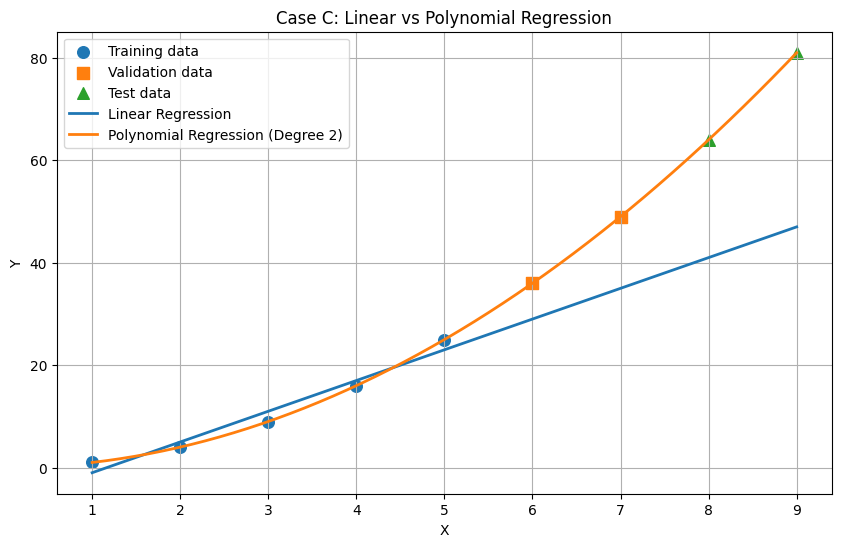

In [ ]:
# 8. Plot actual data and model predictions
X_plot = np.linspace(1, 9, 200).reshape(-1, 1)

linear_plot_pred = linear_model.predict(X_plot)
poly_plot_pred = poly_model.predict(poly.transform(X_plot))

plt.figure(figsize=(10, 6))

plt.scatter(X_train, y_train, label="Training data", s=70)
plt.scatter(X_val, y_val, label="Validation data", s=70, marker="s")
plt.scatter(X_test, y_test, label="Test data", s=70, marker="^")

plt.plot(X_plot, linear_plot_pred,
         label="Linear Regression", linewidth=2)

plt.plot(X_plot, poly_plot_pred,
         label="Polynomial Regression (Degree 2)", linewidth=2)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Case C: Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# 9. Recommend the model based on validation MSE
linear_val_mse = mean_squared_error(y_val, linear_val_pred)
poly_val_mse = mean_squared_error(y_val, poly_val_pred)

print("\nModel Recommendation:")
if poly_val_mse < linear_val_mse:
    print("Polynomial Regression is recommended based on validation MSE.")
elif linear_val_mse < poly_val_mse:
    print("Linear Regression is recommended based on validation MSE.")
else:
    print("Both models have equal validation MSE.")


Model Recommendation:
Polynomial Regression is recommended based on validation MSE.
